In [5]:
# import gevent.monkey #* Handle errors between requests and grequests
# gevent.monkey.patch_all()

import pandas as pd
import numpy as np
from pprint import pprint
import time
import os
import matplotlib.pyplot as plt
from typing import *
import math

In [1]:
#* Constants
startingDate = "2020-01-01"
endingDate = "2023-12-31"

#* Format des données horraires
startingDateInt = "2020010100"
endingDateInt = "2023123123"
regions_departements = {
    "Auvergne-Rhône-Alpes": [
        1, 3, 7, 15, 26, 38, 42, 43, 63, 69, 73, 74
    ],
    "Bourgogne-Franche-Comté": [
        21, 25, 39, 58, 70, 71, 89, 90
    ],
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": [
        18, 28, 36, 37, 41, 45
    ],
    "Corse": [
        20
    ],
    "Grand Est": [
        8, 10, 51, 52, 54, 55, 57, 67, 68, 88
    ],
    "Hauts-de-France": [
        2, 59, 60, 62, 80
    ],
    "Ile-de-France": [
        75, 77, 78, 91, 92, 93, 94, 95
    ],
    "Nouvelle-Aquitaine": [
        16, 17, 19, 23, 24, 33, 40, 47, 64, 79, 86, 87
    ],
    "Normandie": [
        14, 27, 50, 61, 76
    ],
    "Occitanie": [
        9, 11, 12, 30, 31, 32, 34, 46, 48, 65, 66, 81, 82
    ],
    "Pays de la Loire": [
        44, 49, 53, 72, 85
    ],
    "Provence-Alpes-Côte d'Azur": [
        4, 5, 6, 13, 83, 84
    ]
}


In [2]:
"""
Get the meteo data from the gouv API 
"""

APIurl = "https://tabular-api.data.gouv.fr/api/resources/"


#* Colonnes pour les fichier météo en jour
relevantColsDay = ["NUM_POSTE",#* Numéro de poste,
                "AAAAMMJJ", #* Date
                "TN", #* Température minimal à l'abri
                "TX", #* Température maximal à l'abri
                "TM", #* Température moyenne à l'abri
                "TNSOL", #* Température minimal à 10cm du sol
                "TN50", #* Température minimal à 50cm du dol
                "DG", #* Durée du gel
                "FF2M", #* Force moyenne des vents
                "DRR" #* Durée des précipitations
                ]

#* Colonnes pour les fichiers météo en heure
relevantColsHOR = [ "NUM_POSTE",#* Numéro de poste,
                    "AAAAMMJJHH", #* Date et heure
                    "TN", #* Température minimal à l'abri
                    "TX", #* Température maximal à l'abri
                    "T", #* Température à l'abri
                    "TNSOL", #* Température minimal à 10cm du sol
                    "TN50", #* Température minimal à 50cm du dol
                    "DG", #* Durée du gel
                    "FF", #* Force moyenne du vent
                    "DRR1" #* Durée des précipitations sur une heure
                    "RR1" #* Quantitée des précipitations sur l'heure
                    "U", #* Humidité (%)
                    ]

# reponse = requests.get(APIurl+dataIds[0])

# data = pd.DataFrame(reponse.json()['data'])
# data


In [3]:
meteoIds =  []
with  open("HORLinks.txt") as fileIds:
    for link in fileIds:
        meteoIds.append(link[-37:-1])
      
nbDep = len(meteoIds)

In [ ]:
""" SWAGGER AND PROFILE"""
# swagger = requests.get("https://tabular-api.data.gouv.fr/api/resources/c79aaafe-8017-4d2b-8884-57b5391da5bc/swagger/")
# for l in swagger.iter_lines():
#     print(l)
def getProfile():
    import requests
    reponse = requests.get("https://tabular-api.data.gouv.fr/api/resources/9aad7600-6ba8-47c6-b31b-79c8631d7ae9/profile/")
    print(reponse.json()['profile'])
# getProfile()

{'header': ['NUM_POSTE', 'NOM_USUEL', 'LAT', 'LON', 'ALTI', 'AAAAMMJJHH', 'RR1', 'QRR1', 'DRR1', 'QDRR1', 'FF', 'QFF', 'DD', 'QDD', 'FXY', 'QFXY', 'DXY', 'QDXY', 'HXY', 'QHXY', 'FXI', 'QFXI', 'DXI', 'QDXI', 'HXI', 'QHXI', 'FF2', 'QFF2', 'DD2', 'QDD2', 'FXI2', 'QFXI2', 'DXI2', 'QDXI2', 'HXI2', 'QHXI2', 'FXI3S', 'QFXI3S', 'DXI3S', 'QDXI3S', 'HFXI3S', 'QHFXI3S', 'T', 'QT', 'TD', 'QTD', 'TN', 'QTN', 'HTN', 'QHTN', 'TX', 'QTX', 'HTX', 'QHTX', 'DG', 'QDG', 'T10', 'QT10', 'T20', 'QT20', 'T50', 'QT50', 'T100', 'QT100', 'TNSOL', 'QTNSOL', 'TN50', 'QTN50', 'TCHAUSSEE', 'QTCHAUSSEE', 'DHUMEC', 'QDHUMEC', 'U', 'QU', 'UN', 'QUN', 'HUN', 'QHUN', 'UX', 'QUX', 'HUX', 'QHUX', 'DHUMI40', 'QDHUMI40', 'DHUMI80', 'QDHUMI80', 'TSV', 'QTSV', 'PMER', 'QPMER', 'PSTAT', 'QPSTAT', 'PMERMIN', 'QPMERMIN', 'GEOP', 'QGEOP', 'N', 'QN', 'NBAS', 'QNBAS', 'CL', 'QCL', 'CM', 'QCM', 'CH', 'QCH', 'N1', 'QN1', 'C1', 'QC1', 'B1', 'QB1', 'N2', 'QN2', 'C2', 'QC2', 'B2', 'QB2', 'N3', 'QN3', 'C3', 'QC3', 'B3', 'QB3', 'N4', 'QN4'

In [ ]:
#* Test call API
query = (
"page_size=50"
"&columns=NUM_POSTE,AAAAMMJJ,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR"
"&AAAAMMJJ__greater="+startingDate+""
"&AAAAMMJJ__less="+endingDate+""
)
reponse = requests.get("https://tabular-api.data.gouv.fr/api/resources/c79aaafe-8017-4d2b-8884-57b5391da5bc/data/?"+query)
pprint(reponse.json())
if reponse.status_code==200:
    data = pd.DataFrame(reponse.json()['data'])
else:
    pprint(reponse.json())
    
data.head()

{'data': [{'AAAAMMJJ': '2021-01-01',
           'DG': 439,
           'DRR': None,
           'FF2M': None,
           'NUM_POSTE': '01014002',
           'TM': 0.2,
           'TN': -0.1,
           'TN50': None,
           'TNSOL': None,
           'TX': 0.7},
          {'AAAAMMJJ': '2021-01-02',
           'DG': 1096,
           'DRR': None,
           'FF2M': None,
           'NUM_POSTE': '01014002',
           'TM': -0.5,
           'TN': -2.7,
           'TN50': None,
           'TNSOL': None,
           'TX': 0.5},
          {'AAAAMMJJ': '2021-01-03',
           'DG': 1440,
           'DRR': None,
           'FF2M': None,
           'NUM_POSTE': '01014002',
           'TM': -0.8,
           'TN': -1.1,
           'TN50': None,
           'TNSOL': None,
           'TX': -0.1},
          {'AAAAMMJJ': '2021-01-04',
           'DG': 1408,
           'DRR': None,
           'FF2M': None,
           'NUM_POSTE': '01014002',
           'TM': -1.7,
           'TN': -4.1,
           'TN5

,NUM_POSTE,AAAAMMJJ,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR
0,01014002,2021-01-01,-0.1,0.7,0.2,None,None,439,None,None
1,01014002,2021-01-02,-2.7,0.5,-0.5,None,None,1096,None,None
2,01014002,2021-01-03,-1.1,-0.1,-0.8,None,None,1440,None,None
3,01014002,2021-01-04,-4.1,0.5,-1.7,None,None,1408,None,None
4,01014002,2021-01-05,-2.0,0.3,-0.9,None,None,1244,None,None


In [6]:
def getFileName(step:Literal["raw","cleaned"],dataSource:Literal["meteo","energy"],delta:Literal["ByDay","ByHour"]=None,departementNumber:int=None,region:str=None,year:int=None):
    MetoBase = "DEP-"
    if dataSource=="energy":
        if step=="raw":
            # print(os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.zip"))
            return os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.csv")
        else:
            return os.path.join(step+"Data",dataSource,f"Consommation_{region}.csv")
    if dataSource=="meteo":
        if step=="raw":
            number = str(departementNumber) if departementNumber>10 else "0"+str(departementNumber)
            return os.path.join(step+"Data",dataSource,delta,MetoBase+number+".csv")
    
    number = str(departementNumber) if departementNumber>10 else "0"+str(departementNumber)
    return os.path.join(step+"Data",dataSource,MetoBase+number+".csv")

In [ ]:
#* Get all data :
# baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
# query = (
#         "/data/?"
#         "page_size=200"
#         "&columns="+",".join(relevantColsDay)+""
#         "&AAAAMMJJ__greater="+startingDate+"" 
#         "&AAAAMMJJ__less="+endingDate+""
#     )

# #* ~3min per departement
# def getDepMeteoData(id:str):
#     import requests

#     isNext = True
    
#     data = pd.DataFrame()
#     totalRequest = baseAPI+id+query

#     #* Loop throw all pages
#     while isNext:
#         reponse = requests.get(totalRequest)

#         if reponse.status_code==200:
#             reponse = reponse.json()

#             if data.shape[0]>0:
#                 data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together
#             else:
#                 data = pd.DataFrame(reponse['data'])

#             if reponse["links"]["next"]:
#                 totalRequest = reponse["links"]["next"]
#                 time.sleep(0.01) #* The API limit rate is 100/seconds
#             else: #* End of the data
#                 isNext = False

#             print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)

#         else:
#             print('ERROR DURING REQUEST',reponse.json())
#             break
#     print('')
#     return data


# def getMeteoData():
#     for dep,meteoId in list(enumerate(meteoIds))[0:1]:

#         print(f"Département {dep} / {len(meteoIds)}")
#         meteoData = getDepMeteoData(meteoId)
#         print("data size ",meteoData.shape)
#         # time.sleep(5)
#         # meteoData.to_csv(getFileName("raw","meteo",dep))

# getMeteoData()

Département 22 / 95
ERROR DURING REQUEST {'errors': [{'code': 'ae1e4bc88a7143949583c07b1e497822', 'title': 'Database error', 'detail': {'code': '42703', 'details': None, 'hint': 'Perhaps you meant to reference the column "ad4211e1fb9be7075a6f72e397b3f201.AAAAMMJJHH".', 'message': 'column ad4211e1fb9be7075a6f72e397b3f201.AAAAMMJJ does not exist'}}]}

data size  (0, 0)
Département 29 / 95


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
#* -------------- ASYNCRHONOUS BY DAY--------------------
#* Get all data :
apiPageSizeLimit =200
baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
query = (
        "/data/?"
        "page_size="+str(apiPageSizeLimit)+""
        "&columns="+",".join(relevantColsDay)+""
        "&AAAAMMJJ__greater="+startingDate+"" 
        "&AAAAMMJJ__less="+endingDate+""
    )
data = pd.DataFrame()

def handleApiResult(reponse):
    global data
    # print("API HANDLER")
    if reponse.status_code==200:
        reponse = reponse.json()
        print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)
        data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together

    else:
        print('ERROR DURING REQUEST',reponse.json())

#* ~3min per departement
def getDepMeteoDataAsync(dep,id:str):
    global data
    import grequests
    
    totalRequest = baseAPI+id+query
    #* first request : 
    req = grequests.get(totalRequest)
    reponse = grequests.map([req])[0]
    if reponse.status_code==200:
        reponse = reponse.json()

        data = pd.DataFrame(reponse['data'])
        nbPages = math.floor(reponse["meta"]["total"]/reponse["meta"]["page_size"]) #* We already get the first page
        print(f"First call done, Calls to make :{nbPages} ")
        #* Loop throw all pages
        pendingCall = []
        page = 2
        while page < nbPages+1:
            currentRequest = totalRequest + "&page="+str(page)
            pendingCall.append(grequests.get(currentRequest)) 
            if page%100==0: #* We make call by batch of 100
                results = grequests.map(pendingCall)
                print("")
                print(f"Results call for dep {dep}: {results}")
                for result in results:
                    handleApiResult(result)
                time.sleep(1) #* The API limit rate is 100/seconds
                pendingCall = []
                # break
            print('\rnb url to call ',len(pendingCall),end='',flush=True)

            page +=1

        results = grequests.map(pendingCall)
        print(f"Results call for dep {dep}: {results}")  

    else:
        print('ERROR DURING REQUEST',reponse)

    print('')
    return data


def getMeteoData():
    # for dep,meteoId in list(enumerate(meteoIds)):
    for dep in regions_departements['Bretagne']:
        meteoId = meteoIds[dep]
        print(f"Département {dep} / {len(meteoIds)}")
        meteoData = getDepMeteoDataAsync(dep+1,meteoId)
        print(meteoData.head())
        print("data size ",meteoData.shape)
        # time.sleep(5)
        meteoData.to_csv(getFileName("raw","meteo",dep+1))
getMeteoData()

Département 22 / 95
ERROR DURING REQUEST <Response [400]>

Empty DataFrame
Columns: []
Index: []
data size  (0, 0)
Département 29 / 95
ERROR DURING REQUEST <Response [410]>

Empty DataFrame
Columns: []
Index: []
data size  (0, 0)
Département 35 / 95
ERROR DURING REQUEST <Response [400]>

Empty DataFrame
Columns: []
Index: []
data size  (0, 0)
Département 56 / 95
ERROR DURING REQUEST <Response [400]>

Empty DataFrame
Columns: []
Index: []
data size  (0, 0)


C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\gevent\hub.py:161: UserWarning: libuv only supports millisecond timer resolution; all times less will be set to 1 ms
  with loop.timer(seconds, ref=ref) as t:


In [ ]:
#* -------------- ASYNCRHONOUS BY HOUR--------------------
#* Get all data :
apiPageSizeLimit =200
baseAPI = "https://tabular-api.data.gouv.fr/api/resources/"
query = (
        "/data/?"
        "page_size="+str(apiPageSizeLimit)+""
        "&columns="+",".join(relevantColsHOR)+""
        "&AAAAMMJJHH__greater="+startingDateInt+"" 
        "&AAAAMMJJHH__less="+endingDateInt+""
    )
data = pd.DataFrame()

def handleApiResult(reponse):
    global data
    # print("API HANDLER")
    if reponse.status_code==200:
        reponse = reponse.json()
        print(f"\rPage : {reponse['meta']['page']} / {reponse['meta']['total']/reponse['meta']['page_size']} ",end='', flush=True)
        data = pd.concat([data,pd.DataFrame(reponse['data'])]) #* Concat all data together

    else:
        print('ERROR DURING REQUEST',reponse.json())

#* ~3min per departement
def getDepMeteoDataAsync(dep,id:str):
    global data
    import grequests
    
    totalRequest = baseAPI+id+query
    #* first request : 
    req = grequests.get(totalRequest)
    reponse = grequests.map([req])[0]
    if reponse.status_code==200:
        reponse = reponse.json()

        data = pd.DataFrame(reponse['data'])
        nbPages = math.floor(reponse["meta"]["total"]/reponse["meta"]["page_size"]) #* We already get the first page
        print(f"First call done, Calls to make :{nbPages} ")
        #* Loop throw all pages
        pendingCall = []
        page = 2
        while page < nbPages+1:
            currentRequest = totalRequest + "&page="+str(page)
            pendingCall.append(grequests.get(currentRequest)) 
            if page%100==0: #* We make call by batch of 100
                results = grequests.map(pendingCall)
                print("")
                print(f"Results call for dep {dep}: {results}")
                for result in results:
                    handleApiResult(result)
                time.sleep(1) #* The API limit rate is 100/seconds
                pendingCall = []
                # break
            print('\rnb url to call ',len(pendingCall),end='',flush=True)

            page +=1

        results = grequests.map(pendingCall)
        print(f"Results call for dep {dep}: {results}")  

    else:
        print('ERROR DURING REQUEST',reponse)

    print('')
    return data


def getMeteoData():
    # for dep,meteoId in list(enumerate(meteoIds)):
    for dep in regions_departements['Bretagne']:
        meteoId = meteoIds[dep]
        print(f"Département {dep} / {len(meteoIds)}")
        meteoData = getDepMeteoDataAsync(dep+1,meteoId)
        print(meteoData.head())
        print("data size ",meteoData.shape)
        # time.sleep(5)
        meteoData.to_csv(getFileName("raw","meteo",delta="ByHour",departementNumber=dep+1))
getMeteoData()

['9aad7600-6ba8-47c6-b31b-79c8631d7ae9',
 '3ae65545-9ce4-4227-a184-111bad9d0185',
 '32aba64b-69b5-426a-8987-d6f0c469cfc0',
 '47b1abb6-bd3a-4f1b-993d-79ea8b499044',
 '75e05a20-891b-457d-9f9d-958642494517',
 'ab53afc4-ad61-482b-a1ec-1f5f34df2930',
 'a6fadcc9-9118-4943-8c68-63382195a172',
 '08cfeeab-8dfe-48de-9fa5-a733428442dc',
 '1e9f4401-e014-4e67-851a-324066a8c4ad',
 '7ba2f388-88c3-414e-8861-21649515ce9f',
 'a3c3f643-0ed0-436b-b286-86162002da91',
 'abf00c7e-87d6-440a-a36a-c26f2102f27f',
 '2f289284-b98f-47b9-b0d0-ea279c47fabb',
 '0f436b9b-4f83-4006-897a-581d7b0a4a74',
 'baa82970-c867-4503-9adf-16dbf09a2a2e',
 '0bc06b86-5dbb-46f3-bb32-18c63eb1c74c',
 '610a3fe3-be78-4d29-b026-9bcd78ef00a9',
 '8bc056be-c667-42b0-93ba-bfda8c37342f',
 '233b51bc-919c-4c6a-b7ea-29d421572c48',
 '1946fa33-2559-4cc2-b7e8-536b1dae23bb',
 '9ca387ed-901a-4555-833e-e1670f50823c',
 '3618feef-061b-45c8-81e4-050f5facd458',
 '0f74eae5-5d96-490e-b258-622f1e443433',
 '4c28296c-cb58-489c-a690-d4631e028f0b',
 '8b8f15bf-93d8-

C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\gevent\hub.py:161: UserWarning: libuv only supports millisecond timer resolution; all times less will be set to 1 ms
  with loop.timer(seconds, ref=ref) as t:


In [40]:
"""TRANSFORM DATA """

for dep in range(1,nbDep+1):
    rawData = pd.read_csv(getFileName("raw","meteo",dep-1),index_col=0)

    cleanData = rawData.drop(['NUM_POSTE'],axis=1)
    cleanData.groupby(['AAAAMMJJ']).mean() #* Compute the mean by day on differents stations

    cleanData.to_csv(getFileName("cleaned","meteo",dep))

# plt.plot(cleanData["AAAAMMJJ"],cleanData["TN"])


C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\gevent\hub.py:161: UserWarning: libuv only supports millisecond timer resolution; all times less will be set to 1 ms
  with loop.timer(seconds, ref=ref) as t:


In [24]:
"""====================  ENERGY  ===================="""

#* Filtering and agreging the data
# for region in regions_departements.keys():
for region in ["Bretagne"]:

    data20 = pd.read_csv(getFileName('raw',"energy",region=region,year=2020),sep=';',usecols=['Périmètre','Date','Consommation'])
    data21 = pd.read_csv(getFileName('raw',"energy",region=region,year=2021),sep=';',usecols=['Périmètre','Date','Consommation'])
    data22 = pd.read_csv(getFileName('raw',"energy",region=region,year=2022),sep=';',usecols=['Périmètre','Date','Consommation'])
    data23 = pd.read_csv(getFileName('raw',"energy",region=region,year=2023),sep=';',usecols=['Périmètre','Date','Consommation'])
    totalData = pd.concat([data21,data22,data23]).dropna(subset=["Consommation"])
    print(totalData.columns)
    # totalData = totalData[["Périmètre","Date","Consommation"]]
    sumedData = totalData.groupby(["Date"])[["Consommation"]].sum()
    sumedData.to_csv(getFileName("cleaned","energy",region=region))
    # print(sumedData.shape)
    # print(sumedData.head())
    # totalData.to_csv(getFileName("cleaned","energy",region=region))

Index(['Périmètre', 'Date', 'Consommation'], dtype='object')


Index(['TN', 'TX', 'TM', 'TNSOL', 'TN50', 'DG', 'FF2M', 'DRR', 'Date'], dtype='object')


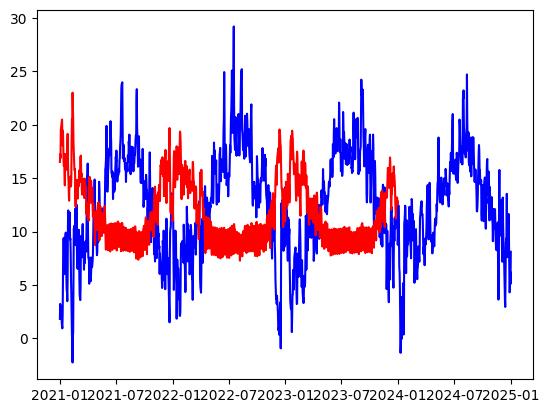

C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\gevent\hub.py:161: UserWarning: libuv only supports millisecond timer resolution; all times less will be set to 1 ms
  with loop.timer(seconds, ref=ref) as t:


In [73]:
#* Check if there exist a correlation

regionTested = "Bretagne"

energyData = pd.read_csv(getFileName("cleaned",'energy',region=regionTested))
# print(energyData)
energyData["Consommation"] = energyData["Consommation"] / 10_000
energyData["Date"] = pd.to_datetime(energyData["Date"])
energyData = energyData.sort_values("Date")
# energyData = energyData.set_index("Date")
departementsData = [pd.read_csv(getFileName("cleaned","meteo",delta="ByDay",departementNumber=dep),index_col=0) for dep in regions_departements[regionTested]]
# print(departementsData[0].head())
departementUnited = pd.concat(departementsData)
# departementUnited
regionAverage = departementUnited.groupby(["AAAAMMJJ"]).mean()
regionAverage["Date"] = pd.to_datetime(regionAverage.index)
regionAverage = regionAverage.dropna()
# regionAverage = regionAverage[regionAverage.index <= energyData.index[-1]]
print(regionAverage.columns)

plt.plot(regionAverage['Date'],regionAverage["TM"],color="blue")
plt.plot(energyData['Date'],energyData["Consommation"],color="red")
plt.show()


In [75]:
#* Premier essai ML 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

#* Ensure that we have the same data for each day : 
combineData = energyData.merge(regionAverage,"inner",left_on="Date",right_on="Date")

d= 3
poly = PolynomialFeatures(d)

linReg = LinearRegression()

# features = combineData.drop(["Date","Consommation"],axis=1).to_numpy()
features = combineData[["TN","DRR"]].to_numpy()
y = combineData[["Consommation"]].to_numpy()

X = poly.fit_transform(features)
Xtrain,Xtest, yTrain, yTest = train_test_split(X,y,test_size=0.2)

# XtrainPoly = poly.fit_transform(Xtrain)
# XtestPoly = poly.fit_transform(Xtest)

linReg.fit(Xtrain,yTrain)
linReg.score(Xtest,yTest)



print(f'The regression coef {linReg.coef_}')
print(f'The R^2 determination coef {linReg.score(Xtest,yTest)}')    
print(f'The RSS {mean_squared_error(yTest,linReg.predict(Xtest))}')    

# linReg.score(XtrainPoly,yTrain)
# X.shape, y.shape
# regionAverage.tail(), energyData.tail()
# combineData

The regression coef [[ 0.00000000e+00 -8.17766960e-01  1.13987589e-02  1.04479764e-02
   3.79336933e-04 -2.01270773e-05  8.42014823e-04 -6.01920897e-05
   7.13881519e-07  5.97235583e-09]]
The R^2 determination coef 0.6967498212020873
The RSS 2.3075556138884235


C:\Users\felib\AppData\Roaming\Python\Python313\site-packages\gevent\hub.py:161: UserWarning: libuv only supports millisecond timer resolution; all times less will be set to 1 ms
  with loop.timer(seconds, ref=ref) as t:


In [ ]:
xs = np.linspace(min(combineData["Date"]), xMax, 250)
xsExtend = poly.fit_transform(xs.reshape(-1,1))
ysPredict = reg.predict(xsExtend)

plt.plot(x,y,'bo')

plt.plot(xs,ysPredict)
plt.show()

      AAAAMMJJ   TN    TX   TM  TNSOL  TN50     DG  FF2M   DRR
0   2021-01-01 -2.9   5.6  0.3   -5.1   NaN  742.0   NaN   NaN
1   2021-01-02 -0.5   7.0  2.7   -2.1   NaN    0.0   NaN   NaN
2   2021-01-03  0.2   3.4  1.6   -0.3   NaN    0.0   NaN   NaN
3   2021-01-04 -0.2   5.1  2.5   -1.6   NaN   41.0   NaN   NaN
4   2021-01-05  1.1   5.0  2.4   -0.5   NaN    0.0   NaN   NaN
..         ...  ...   ...  ...    ...   ...    ...   ...   ...
6   2024-12-27  3.4   4.8  3.7    3.5   3.5    0.0   NaN   0.0
7   2024-12-28  1.0   6.8  4.0    1.3   1.2    0.0   NaN  77.0
8   2024-12-29  5.5   7.9  6.9    5.4   5.3    0.0   NaN  38.0
9   2024-12-30  5.1   6.1  5.6    5.5   5.5    0.0   NaN  24.0
10  2024-12-31  4.4  11.3  7.7    3.4   3.9    0.0   NaN   0.0

[29211 rows x 9 columns]
       AAAAMMJJ    TN    TX    TM  TNSOL  TN50   DG  FF2M  DRR
0    2022-05-12   5.4  17.1  11.0    NaN   NaN  0.0   NaN  NaN
1    2022-05-13   3.8  18.5  11.5    NaN   NaN  0.0   NaN  NaN
2    2022-05-14   2.1  23.1  

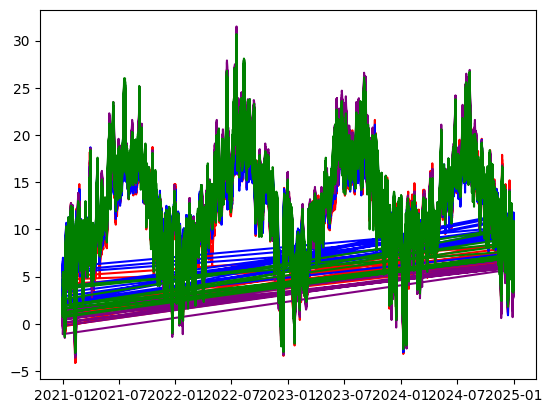

In [26]:
departementsData = [pd.read_csv(getFileName("cleaned","meteo",dep),index_col=0) for dep in regions_departements[regionTested]]
colors = ["red","blue","purple","green","orange","black","cyan","gray"]
for d,departementDF in enumerate(departementsData):
    print(departementDF)
    plt.plot(pd.to_datetime(departementDF['AAAAMMJJ']),departementDF["TM"],color=colors[d])
plt.show()